# LandscapeSHAP demo: which persistent homology class gets the credit?

This notebook:

1. Samples 1000-point orbits from a coupled logistic-type torus map, for 5 values of `r`, 100 initial conditions each (500 point clouds total).
2. Computes degree-1 persistent homology (H1) with the **alpha complex** (GUDHI).
3. Builds fixed-length features per point cloud: a 15-layer **persistence landscape**.
4. Trains a **linear multiclass SVM** to predict `r` from these features.
5. Computes **exact, closed-form Shapley values** for every point in a persistence diagram (no permutation sampling — see the accompanying write-up, *LandscapeSHAP: Which Persistent Homology Class Gets the Credit?*).
6. Plots 5 example diagrams colored by Shapley value; for each of the top-5 |Shapley| points, shows the alpha-complex triangulation **at that point's birth time**, with the newly-born H1 cycle drawn in the same color as the point in the diagram.

**Design choices made where the request was ambiguous** (documented again at the end of the notebook): filtration grid range and noise threshold are picked adaptively from the data; the representative cycle for each point is reconstructed via breadth-first search (fewest hops), not a globally minimal-weight cycle, which is a harder problem GUDHI's high-level API does not solve directly.


In [1]:
!pip install -q gudhi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 14.7 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import gudhi
from collections import deque, defaultdict
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)


## 1. Dynamical system: sample the point clouds

$$x_{n+1} = x_n + r\cdot y_n(1-y_n) \bmod 1, \qquad y_{n+1} = y_n + r\cdot x_{n+1}(1-x_{n+1}) \bmod 1$$

For each `r` in `{2, 3.5, 4, 4.1, 4.3}` we draw 100 independent initial conditions, burn in
500 iterations to leave the transient, then record 1000 consecutive iterates as one point
cloud (label = `r`). That gives 500 point clouds of 1000 points each.


In [3]:
def sample_orbit(r, n_points=1000, burn_in=500, rng=None):
    """Iterate the coupled torus map and return n_points samples on the attractor."""
    rng = rng or np.random.default_rng()
    x, y = rng.uniform(), rng.uniform()
    for _ in range(burn_in):
        x = (x + r * y * (1.0 - y)) % 1.0
        y = (y + r * x * (1.0 - x)) % 1.0
    pts = np.empty((n_points, 2))
    for i in range(n_points):
        x = (x + r * y * (1.0 - y)) % 1.0
        y = (y + r * x * (1.0 - x)) % 1.0
        pts[i, 0] = x
        pts[i, 1] = y
    return pts

R_VALUES = [2.0, 3.5, 4.0, 4.1, 4.3]
N_CLOUDS_PER_R = 100
N_POINTS = 1000

point_clouds, labels = [], []
for r in R_VALUES:
    for _ in range(N_CLOUDS_PER_R):
        point_clouds.append(sample_orbit(r, n_points=N_POINTS, burn_in=500, rng=rng))
        labels.append(r)
labels = np.array(labels)
print(f"Generated {len(point_clouds)} point clouds, {N_POINTS} points each.")

# One fixed example point cloud per r, chosen once here and reused for every plot in this
# notebook (the sanity-check plot below, and the diagrams / triangulations in Section 6) so
# they all refer to the exact same 5 clouds.
EXAMPLE_INDICES = [int(np.where(labels == r)[0][0]) for r in R_VALUES]


Generated 500 point clouds, 1000 points each.


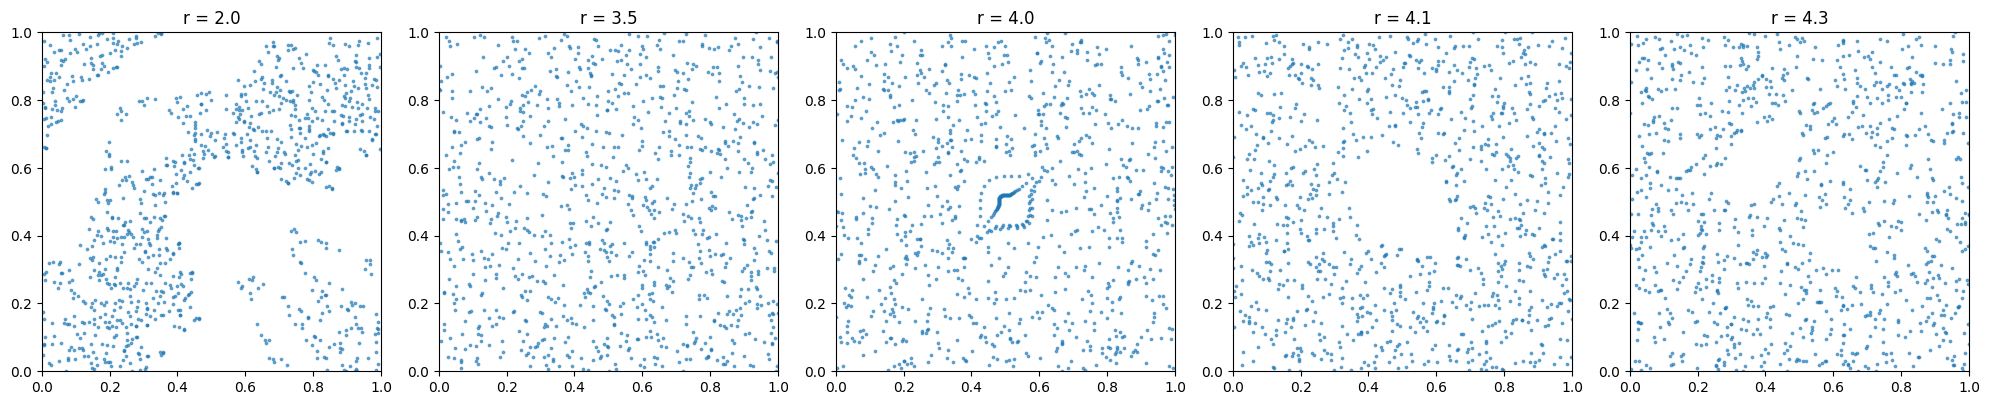

In [4]:
# Quick visual sanity check: the same 5 example point clouds used later in the notebook.
fig, axes = plt.subplots(1, len(R_VALUES), figsize=(4 * len(R_VALUES), 4))
for ax, idx in zip(axes, EXAMPLE_INDICES):
    ax.scatter(point_clouds[idx][:, 0], point_clouds[idx][:, 1], s=3, alpha=0.6)
    ax.set_title(f"r = {labels[idx]}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## 2. Persistent homology (H1, alpha complex)

GUDHI's `AlphaComplex` filtration values are the *squared* alpha radius; we take a square
root so birth/death values sit on the same length scale as the point coordinates. We keep,
for every H1 pair, not just `(birth, death)` but also the exact **birth-edge** (2 vertices)
and **death-triangle** (3 vertices) that the persistence algorithm paired it with — this is
what lets us trace a diagram point back to actual point-cloud points later on.

The noise threshold and the feature grid are both picked *after* a first pass over the whole
dataset, so they're calibrated to the actual scale of this data rather than guessed.


In [5]:
def compute_h1(points):
    """H1 persistence pairs for a 2D point cloud via the alpha complex.
    Returns a list of (birth, death, birth_simplex, death_simplex) tuples;
    birth_simplex/death_simplex are lists of vertex indices into `points`."""
    ac = gudhi.AlphaComplex(points=points)
    st = ac.create_simplex_tree()
    st.persistence(homology_coeff_field=2, min_persistence=0)
    h1 = []
    for birth_s, death_s in st.persistence_pairs():
        if len(birth_s) == 2 and len(death_s) == 3:
            b = np.sqrt(max(st.filtration(birth_s), 0.0))
            d = np.sqrt(max(st.filtration(death_s), 0.0))
            h1.append((b, d, birth_s, death_s))
    return h1

raw_h1 = [compute_h1(pc) for pc in point_clouds]

NOISE_FRAC = 0.02  # drop H1 pairs whose persistence is below this fraction of GRID_MAX
all_deaths = np.concatenate([[p[1] for p in h1] for h1 in raw_h1 if h1])
GRID_MAX = float(np.percentile(all_deaths, 99) * 1.1)
EPSILON = NOISE_FRAC * GRID_MAX
M = 100
grid = np.linspace(0.0, GRID_MAX, M)
print(f"Grid max: {GRID_MAX:.4f}   noise threshold: {EPSILON:.5f}")

def filter_h1(h1):
    return [p for p in h1 if (p[1] - p[0]) > EPSILON]

h1_diagrams = [filter_h1(h1) for h1 in raw_h1]
print("Median / min / max surviving H1 features per cloud:",
      np.median([len(h) for h in h1_diagrams]),
      np.min([len(h) for h in h1_diagrams]),
      np.max([len(h) for h in h1_diagrams]))


Grid max: 0.0541   noise threshold: 0.00108
Median / min / max surviving H1 features per cloud: 320.0 1 376


## 3. Featurization: persistence landscapes

`K = 15` landscape layers, zero-padded when a diagram has fewer than 15 surviving H1
features.


In [6]:
K = 15  # number of landscape layers

def landscape(h1, grid, K):
    N = len(h1)
    M = len(grid)
    if N == 0:
        return np.zeros((K, M))
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    tent = np.minimum(np.maximum(0.0, grid[None, :] - b[:, None]),
                       np.maximum(0.0, d[:, None] - grid[None, :]))  # (N, M)
    sorted_tent = np.sort(tent, axis=0)[::-1]
    L = np.zeros((K, M))
    L[:min(K, N)] = sorted_tent[:min(K, N)]
    return L

landscapes = [landscape(h1, grid, K).flatten() for h1 in h1_diagrams]
X = np.array(landscapes)  # (n_samples, K*M)
print("Feature matrix:", X.shape)


Feature matrix: (500, 1500)


## 4. Train a linear multiclass SVM

`labels` holds the *numeric* `r` used throughout for grouping/plotting. scikit-learn's
`LinearSVC` refuses to fit on that directly: since `r` includes non-integer floats
(3.5, 4.1, 4.3), sklearn's target-type check classifies a plain float array as a
**regression** target ("continuous"), not a multiclass label, even though there are only 5
distinct values repeated many times (`ValueError: Unknown label type: continuous`). The fix
is to hand the classifier a categorical encoding of `r` instead -- here, its `%g`-formatted
string -- while keeping `labels` itself numeric for everything else in the notebook.


In [7]:
def r_to_label(r):
    return f"{r:g}"  # e.g. 4.0 -> "4", 4.1 -> "4.1" -- a clean, distinct string per class

y = np.array([r_to_label(r) for r in labels])

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(y)), test_size=0.25, stratify=y, random_state=RNG_SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

model = LinearSVC(C=1.0, multi_class="ovr", max_iter=20000)
model.fit(X_train_s, y_train)
print("Test accuracy:", model.score(X_test_s, y_test))
print("Classes:", model.classes_)


Test accuracy: 0.792
Classes: ['2' '3.5' '4' '4.1' '4.3']


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## 5. Exact, closed-form point-level Shapley values (LandscapeSHAP)

For a linear model, the Shapley value of every persistence-diagram point decomposes exactly
across the feature vector's cells (the landscape cells), and each cell's exact Shapley value
has a closed form from sorting alone (Theorem 1 in the write-up):
for values $t_{(1)}\ge\cdots\ge t_{(N)}$ sorted descending and $t_{(N+1)}:=0$, the player at
rank $r$ has Shapley value $\sum_{j=\max(r,k+1)}^{N}(t_{(j)}-t_{(j+1)})/j$ for the $k$-th
order-statistic ($k$-th largest, 0-indexed) game. No permutation sampling anywhere below.

We first re-run the same brute-force check from the write-up, at small scale, so you can
confirm the formula is implemented correctly in *this* environment before trusting it on
real data.


In [8]:
def order_stat_suffix(values):
    """values: 1D array of raw (non-negative) values for one 'column' game.
    Returns (order, S) with S[j-1] = S_j = sum_{j'=j}^{N} (t_(j')-t_(j'+1))/j'  (1-indexed j),
    and S[N] = 0 appended, so phi for rank r at layer k is S[max(r,k+1)-1]."""
    N = len(values)
    order = np.argsort(-values, kind="stable")
    tsort = values[order]
    tpad = np.append(tsort, 0.0)
    j = np.arange(1, N + 1)
    gaps = tpad[:-1] - tpad[1:]
    terms = gaps / j
    suffix = np.cumsum(terms[::-1])[::-1]
    return order, np.append(suffix, 0.0)

def column_all_layers_shapley(values, K, weights):
    """Exact Shapley contribution of every player (original order), summed over layers
    k=0..K-1 of the SAME column, weighted by `weights[k]`. One sort, O(K) lookups."""
    N = len(values)
    if N == 0:
        return np.zeros(0)
    order, S = order_stat_suffix(values)
    rank_of = np.empty(N, dtype=int)
    rank_of[order] = np.arange(1, N + 1)
    contrib = np.zeros(N)
    for k in range(K):
        idx = np.maximum(rank_of, k + 1) - 1
        contrib += weights[k] * S[idx]
    return contrib

def point_shapley(h1, grid, K, w_landscape):
    """w_landscape: (K, M) rescaled weights for the landscape block."""
    N = len(h1)
    if N == 0:
        return np.zeros(0)
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    phi = np.zeros(N)
    for m, gm in enumerate(grid):
        tent_m = np.minimum(np.maximum(0.0, gm - b), np.maximum(0.0, d - gm))
        phi += column_all_layers_shapley(tent_m, K, w_landscape[:, m])
    return phi

def rescaled_weights(model, scaler, class_label, K, M):
    """w_hat = w / sigma on the RAW (unscaled) feature vector; intercept term cancels
    exactly for Shapley purposes, see write-up Section 6."""
    c = list(model.classes_).index(class_label)
    w_full = model.coef_[c] / scaler.scale_
    return w_full.reshape(K, M), w_full


In [9]:
# Self-check: closed form vs brute-force permutation Shapley on small random examples.
import itertools

def brute_force_column_shapley(values, k):
    N = len(values)
    def v(idx_set):
        if len(idx_set) <= k:
            return 0.0
        return sorted((values[i] for i in idx_set), reverse=True)[k]
    phi = np.zeros(N)
    perms = list(itertools.permutations(range(N)))
    for perm in perms:
        coalition, v_prev = [], v([])
        for p in perm:
            coalition.append(p)
            v_cur = v(coalition)
            phi[p] += v_cur - v_prev
            v_prev = v_cur
    return phi / len(perms)

check_rng = np.random.default_rng(0)
max_err = 0.0
for _ in range(20):
    N = check_rng.integers(2, 6)
    vals = check_rng.uniform(0, 5, size=N)
    for k in range(N + 1):
        order, S = order_stat_suffix(vals)
        rank_of = np.empty(N, dtype=int)
        rank_of[order] = np.arange(1, N + 1)
        phi_cf = S[np.maximum(rank_of, k + 1) - 1]
        phi_bf = brute_force_column_shapley(vals, k)
        max_err = max(max_err, np.max(np.abs(phi_cf - phi_bf)))
print("Max abs error vs brute force:", max_err, "-> OK" if max_err < 1e-8 else "-> MISMATCH, stop and check")


Max abs error vs brute force: 2.220446049250313e-15 -> OK


## 6. Plot 5 example diagrams colored by Shapley value, and show the
triangulation + newly-born cycle at each top-5 point's birth time

These are the **same 5 point clouds** plotted in Section 1 (`EXAMPLE_INDICES`), so the raw
point cloud, its diagram, and its Shapley explanation all refer to one consistent example per
`r`. We explain the model's score for each cloud's **true** class; the printed `sum(phi)` vs
`Delta` line is the efficiency-axiom check, exact to numerical precision since nothing here
is sampled.

For the 5 diagram points with the largest |Shapley value|, we reconstruct, **at that point's
own birth time**, the full alpha-complex triangulation as it stood at that instant (thin gray
edges, over the *whole* point cloud -- no cropping), and draw the actual **cycle of edges
that becomes a new, independent H1 generator right then** -- in the same color that point has
in the persistence diagram (the diverging Shapley colormap). Each of the 5 points generally
has a different birth time, so each gets its own snapshot of the triangulation at that
moment.

*How the cycle is found:* an edge creates a new H1 class (rather than just merging two
connected components) exactly when its two endpoints are **already connected** by some path
through earlier edges -- that's the standard combinatorial characterization of a
1-dimensional birth as a filtration grows. So we breadth-first search for that pre-existing
connecting path among edges strictly earlier than the birth time, and close it into a loop
with the birth edge itself. That gives a genuine, closed representative cycle for the class
(not just its single generating edge) -- though it's the fewest-*hops* path BFS finds, not
necessarily the geometrically shortest or homologically minimal-weight one (see the caveat
at the end of the notebook).


In [10]:
def compute_edges(points):
    """All 1-simplices (edges) of the alpha complex, with filtration values (sqrt'd to
    match the birth/death scale used elsewhere)."""
    ac = gudhi.AlphaComplex(points=points)
    st = ac.create_simplex_tree()
    return [(s[0], s[1], np.sqrt(max(f, 0.0))) for s, f in st.get_skeleton(1) if len(s) == 2]

def representative_cycle(edges, u, v, birth_time, eps=1e-9):
    """BFS shortest path from u to v using only edges strictly earlier than birth_time.
    u and v are guaranteed connected before birth_time -- that is precisely why adding the
    (u, v) edge creates a new H1 class instead of merging two components. Closing this path
    with the (u, v) edge gives a genuine cycle representing the newly-born class."""
    adj = defaultdict(list)
    for i, j, f in edges:
        if f < birth_time - eps:
            adj[i].append(j)
            adj[j].append(i)
    if u == v:
        return [u]
    visited = {u: None}
    queue = deque([u])
    while queue:
        cur = queue.popleft()
        if cur == v:
            break
        for nxt in adj[cur]:
            if nxt not in visited:
                visited[nxt] = cur
                queue.append(nxt)
    if v not in visited:
        return [u, v]  # fallback; shouldn't happen for a genuine H1 birth edge
    path = [v]
    while path[-1] != u:
        path.append(visited[path[-1]])
    path.reverse()
    return path


r= 2.0: sum(phi)= 2.839869   Delta= 2.839869   |diff|=0.00e+00   predicted=2
r= 3.5: sum(phi)= 0.762738   Delta= 0.762738   |diff|=1.11e-16   predicted=3.5
r= 4.0: sum(phi)= 3.499206   Delta= 3.499206   |diff|=0.00e+00   predicted=3.5
r= 4.1: sum(phi)= 2.123190   Delta= 2.123190   |diff|=8.88e-16   predicted=4.1
r= 4.3: sum(phi)= 5.163410   Delta= 5.163410   |diff|=8.88e-16   predicted=4.3


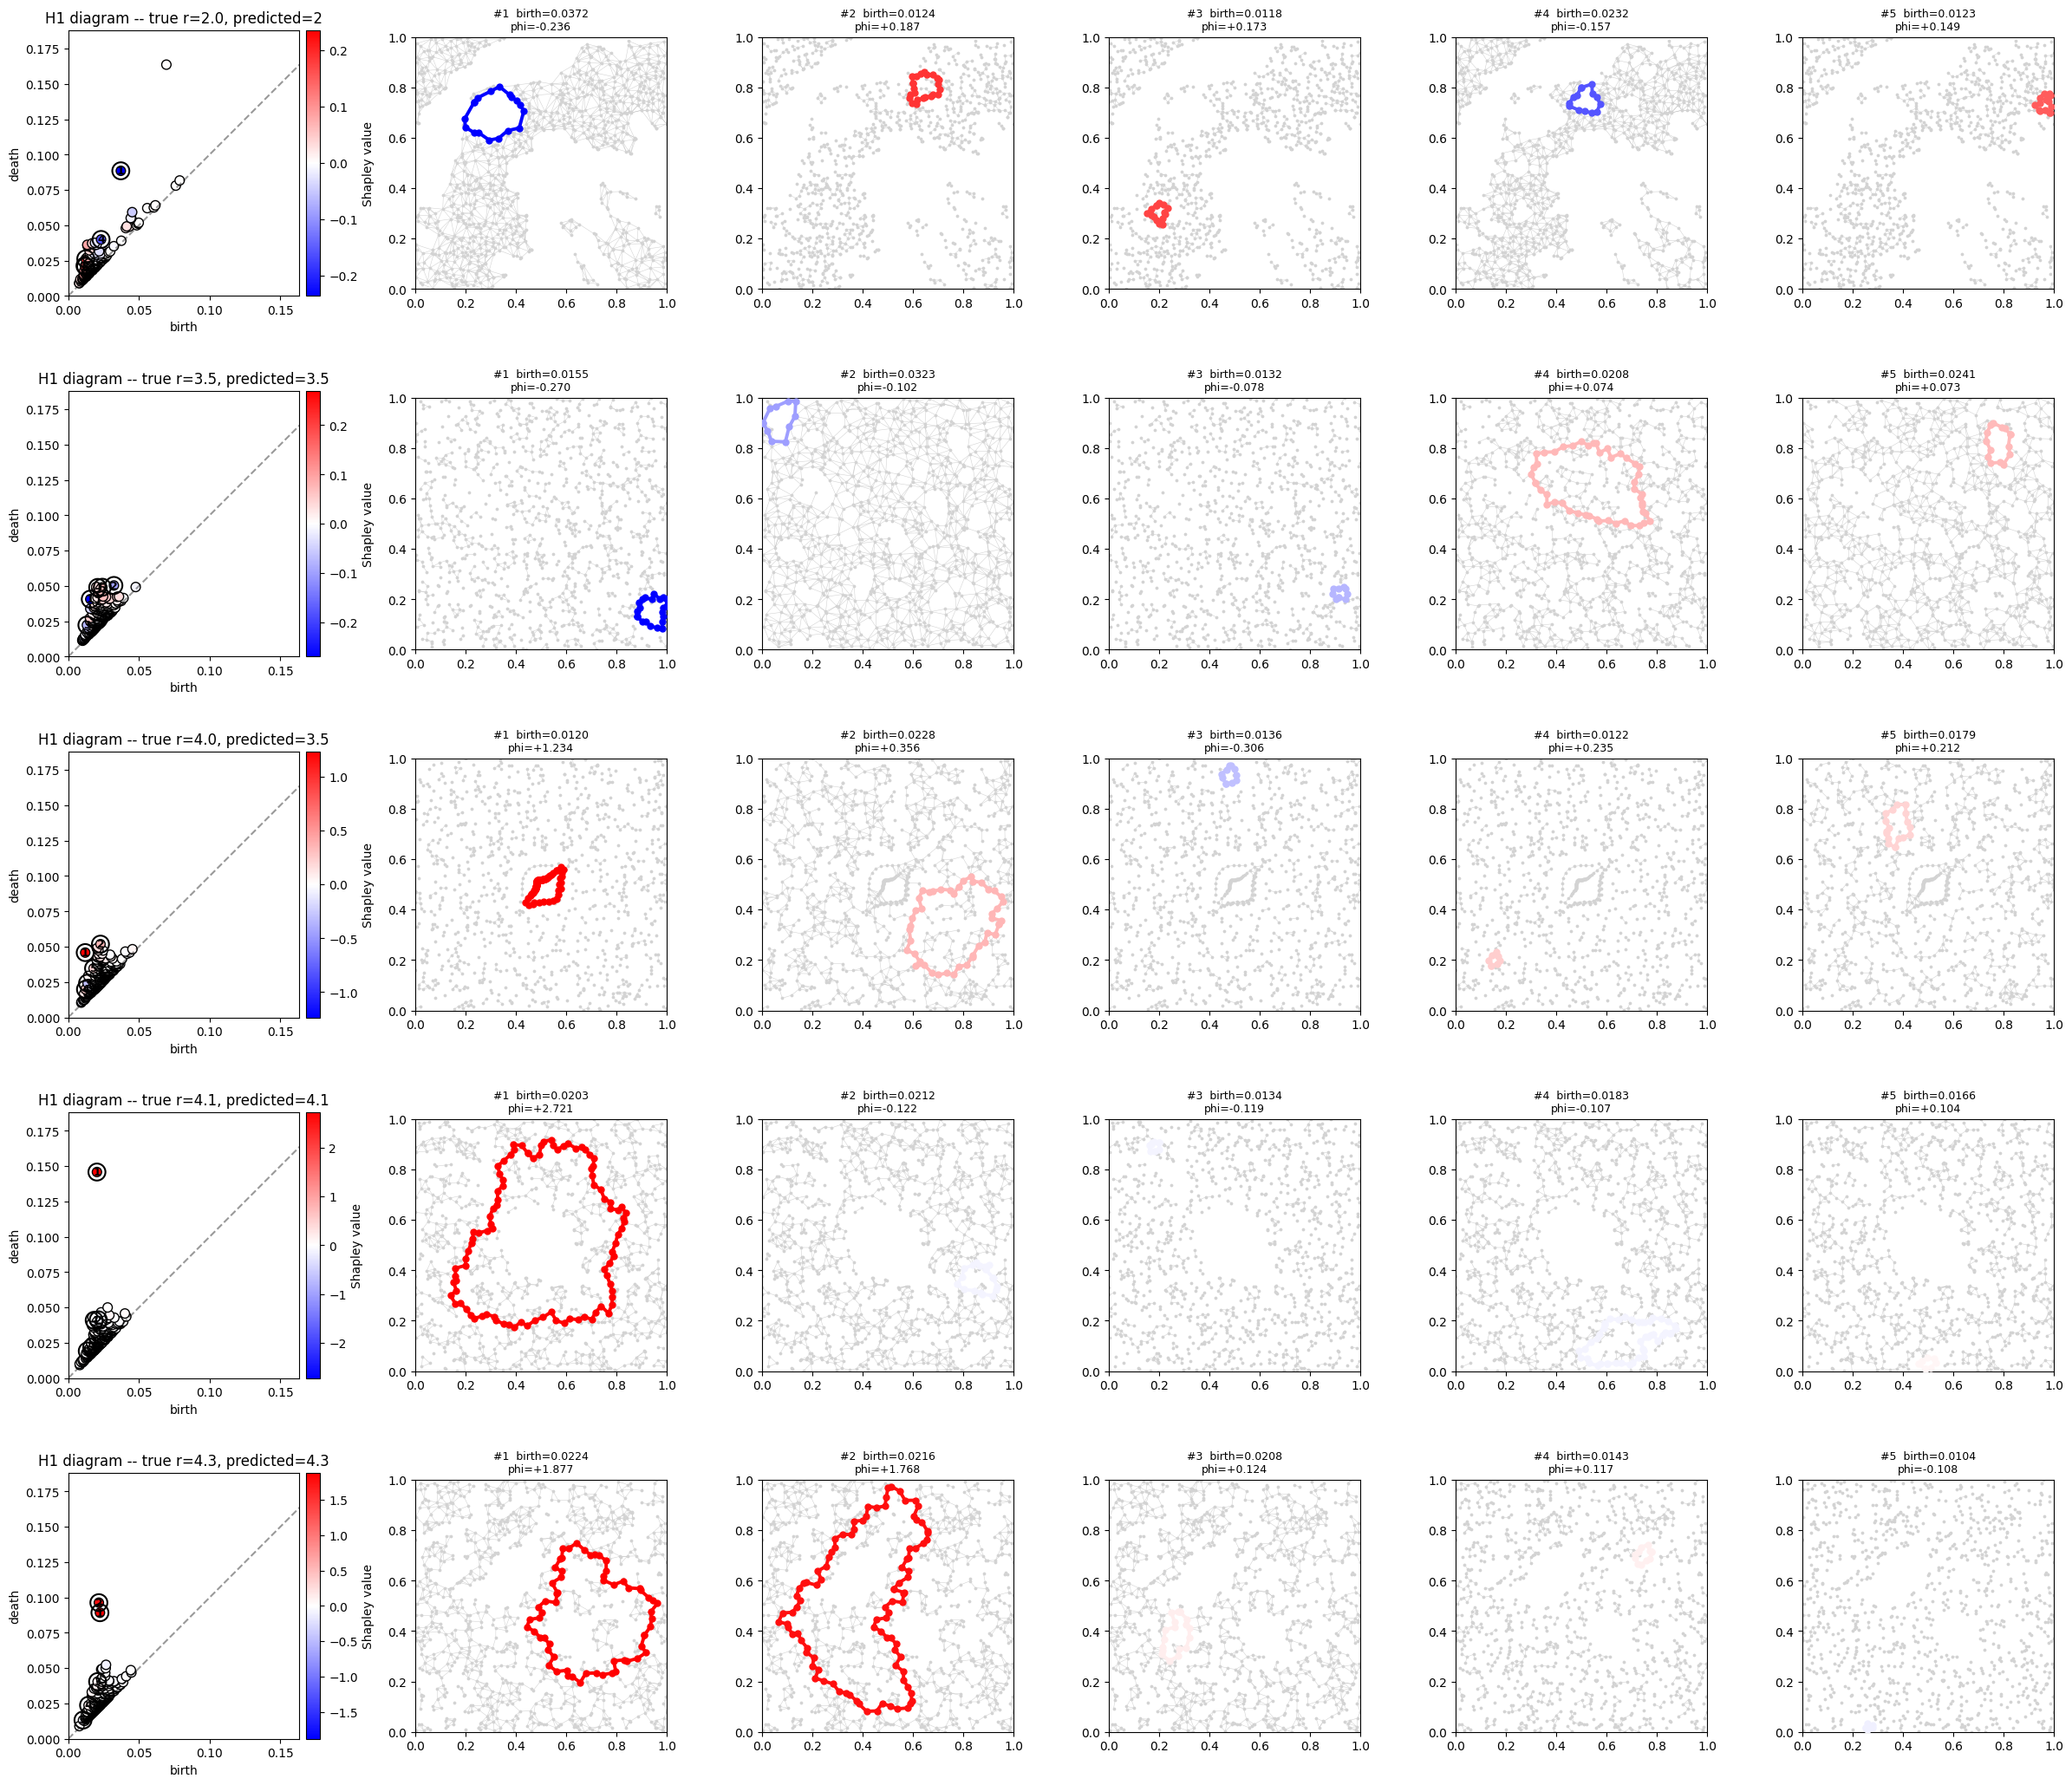

In [11]:
# Reuse the exact same 5 clouds shown in Section 1. (If one of them happens to have no
# surviving H1 features after filtering -- essentially impossible at 1000 points/cloud but
# guarded anyway -- it is skipped here.)
example_indices = [idx for idx in EXAMPLE_INDICES if len(h1_diagrams[idx]) > 0]
if len(example_indices) < len(EXAMPLE_INDICES):
    print(f"Note: {len(EXAMPLE_INDICES) - len(example_indices)} example cloud(s) had no "
          "surviving H1 features and were skipped.")

N_TOP = 5
cmap = plt.cm.bwr
fig, axes = plt.subplots(len(example_indices), 1 + N_TOP,
                          figsize=(4 * (1 + N_TOP), 4.2 * len(example_indices)))

# The largest death coordinate actually appearing among the diagrams we're about to plot --
# NOT GRID_MAX, which is a 99th-percentile cutoff over the whole 500-cloud dataset used to
# size the landscape feature grid and is deliberately allowed to sit below individual
# diagrams' true max (that's what makes it a noise-trimmed grid rather than a display range).
# Using GRID_MAX here would silently crop real points off the visible frame.
PLOT_MAX = max(max(p[1] for p in h1_diagrams[idx]) for idx in example_indices)

for row, idx in enumerate(example_indices):
    h1 = h1_diagrams[idx]
    true_r = labels[idx]
    w_land, w_full = rescaled_weights(model, scaler, r_to_label(true_r), K, M)
    phi = point_shapley(h1, grid, K, w_land)
    delta = float(np.dot(w_full, X[idx]))  # f_raw(x) - f_raw(0); intercept cancels exactly
    pred = model.predict(scaler.transform(X[idx:idx + 1]))[0]
    print(f"r={true_r:>4}: sum(phi)={phi.sum(): .6f}   Delta={delta: .6f}   "
          f"|diff|={abs(phi.sum() - delta):.2e}   predicted={pred}")

    b_arr = np.array([p[0] for p in h1])
    d_arr = np.array([p[1] for p in h1])
    vmax = max(np.max(np.abs(phi)), 1e-8)
    norm = plt.Normalize(vmin=-vmax, vmax=vmax)

    ax = axes[row, 0]
    sc = ax.scatter(b_arr, d_arr, c=phi, cmap=cmap, norm=norm, s=60, edgecolors="k")
    ax.plot([0, PLOT_MAX], [0, PLOT_MAX], "k--", alpha=0.4)
    ax.set_title(f"H1 diagram -- true r={true_r}, predicted={pred}")
    ax.set_xlabel("birth"); ax.set_ylabel("death")
    # Same birth/death scale on every row's diagram (shared PLOT_MAX, the true max death
    # coordinate among the plotted diagrams), so the 5 examples are visually comparable rather
    # than each auto-scaling to its own point range, and no real point ends up cropped off. A
    # bit of headroom above PLOT_MAX on the death axis only, so the top-most points and the
    # birth==death diagonal aren't crowded against the frame.
    ax.set_xlim(0, PLOT_MAX)
    ax.set_ylim(0, PLOT_MAX * 1.15)
    ax.set_aspect("equal")
    # Attach the colorbar as a same-height axes carved out of ax itself (rather than
    # plt.colorbar's default, which sizes off the *pre-aspect-lock* bounding box -- with
    # set_aspect("equal") the diagram axes end up shorter than that box once rendered, so the
    # default colorbar comes out taller than the diagram and spills into neighboring text).
    cax = make_axes_locatable(ax).append_axes("right", size="6%", pad=0.08)
    plt.colorbar(sc, cax=cax, label="Shapley value")

    n_top_here = min(N_TOP, len(phi))
    top_idx = np.argsort(-np.abs(phi))[:n_top_here]
    ax.scatter(b_arr[top_idx], d_arr[top_idx], facecolors="none", edgecolors="k",
               s=200, linewidths=1.5)
    for rank, j in enumerate(top_idx):
        ax.annotate(str(rank + 1), (b_arr[j], d_arr[j]), fontsize=9, weight="bold",
                     ha="center", va="center")

    pc = point_clouds[idx]
    edges = compute_edges(pc)

    for col in range(N_TOP):
        ax2 = axes[row, 1 + col]
        if col >= n_top_here:
            ax2.axis("off")
            continue
        j = top_idx[col]
        birth_time, death_time, birth_s, death_s = h1[j]
        color = cmap(norm(phi[j]))

        # background: the triangulation as it stood at this point's birth time
        for i0, i1, f in edges:
            if f <= birth_time + 1e-9:
                p0, p1 = pc[i0], pc[i1]
                ax2.plot([p0[0], p1[0]], [p0[1], p1[1]], color="gray",
                          linewidth=0.4, alpha=0.35, zorder=1)
        ax2.scatter(pc[:, 0], pc[:, 1], s=3, color="lightgray", zorder=2)

        u, v = birth_s
        path = representative_cycle(edges, u, v, birth_time)
        loop = path + [path[0]]  # close it with the birth edge (v -> u)
        loop_xy = pc[loop]
        ax2.plot(loop_xy[:, 0], loop_xy[:, 1], "-", color=color, linewidth=2.8, zorder=5)
        ax2.scatter(loop_xy[:, 0], loop_xy[:, 1], color=color, s=25, zorder=6)

        ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)  # whole point cloud, no cropping
        ax2.set_aspect("equal")
        ax2.set_title(f"#{col + 1}  birth={birth_time:.4f}\nphi={phi[j]:+.3f}", fontsize=9)

plt.tight_layout()
fig.savefig('dynamics_linear_shap_representative_cycles.svg', format="svg", bbox_inches="tight")
plt.show()


## Notes on design choices / caveats

- **Grid range / noise threshold.** `GRID_MAX` is the 99th percentile of all observed death
  values (times 1.1), and the noise threshold is 2% of `GRID_MAX`. Both are data-driven
  defaults, not fixed constants -- re-tune `NOISE_FRAC` if the surviving-feature counts
  printed in Section 2 look too high or too low for your taste.
- **Which class is explained.** Each example explains the linear score for the point cloud's
  *true* `r`, not necessarily the predicted class -- if `predicted != true r` in the printed
  line, the plotted attribution is still exactly correct, just for the true-class score
  rather than the model's actual top pick.
- **Example clouds aren't guaranteed held-out.** `EXAMPLE_INDICES` is fixed right after the
  point clouds are generated (Section 1), before the train/test split exists, so a given
  example may land in either split -- the point was to keep one consistent cloud per `r`
  across the whole notebook, not to guarantee an unseen-during-training explanation. Intersect
  `EXAMPLE_INDICES` with `idx_test` after Section 4 if you specifically want held-out examples.
- **Representative cycle.** For each top-5 point we reconstruct a genuine closed loop (not
  just the generating edge): the birth edge's two endpoints are guaranteed to already be
  connected using only earlier edges (that is precisely what makes the edge a birth rather
  than an H0 merge), so a breadth-first search between them over that earlier-edge graph,
  closed with the birth edge, gives a real representative cycle for the class. It is the
  fewest-*hops* path BFS finds, though -- not a globally minimal-*weight* cycle, which is a
  harder (generally NP-hard) problem GUDHI's high-level API does not solve directly. If the
  loops look unnecessarily jagged, swapping the BFS for Euclidean-length-weighted Dijkstra
  over the same edge set is a small, self-contained change to `representative_cycle`.
